In [ ]:
from google.colab import drive
import os, gc, torch

drive.mount('/content/drive')

# Verify GPU
print("Device:", torch.cuda.get_device_name(0))
print(f"Available VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

# Clean any residual memory
gc.collect()
torch.cuda.empty_cache()

# Install dependencies
!pip install -q git+https://github.com/facebookresearch/segment-anything.git
!pip install -q timm pysodmetrics opencv-python pillow tqdm matplotlib

Mounted at /content/drive
Device: Tesla T4
Available VRAM: 15.64 GB
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 15.6 MB/s eta 0:00:00


In [ ]:
import urllib.request

# Setup folders in Colab local scratch space for speed
!mkdir -p /content/checkpoints /content/dataset/COD10K-v3 /content/cached_feats

# Download SAM ViT-B checkpoint (~375 MB)
sam_ckpt = "/content/checkpoints/sam_vit_b_01ec64.pth"
if not os.path.exists(sam_ckpt):
    print("Downloading SAM ViT-B weights...")
    urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth", sam_ckpt)
    print("Downloaded successfully.")

# If you stored the dataset zip in Google Drive, copy & unzip it:
# !cp /content/drive/MyDrive/COD10K-v3.zip /content/dataset/
# !unzip -q /content/dataset/COD10K-v3.zip -d /content/dataset/

Downloaded successfully.


In [ ]:
import glob
from PIL import Image
from tqdm import tqdm
import torchvision.transforms as T
from segment_anything import sam_model_registry

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load base SAM model in pure evaluation mode
sam = sam_model_registry["vit_b"](checkpoint=sam_ckpt).to(device)
sam.eval()

img_dir = "/content/dataset/COD10K-v3/Train/Image"
cache_dir = "/content/cached_feats"
os.makedirs(cache_dir, exist_ok=True)

img_paths = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))
print(f"Total images to cache: {len(img_paths)}")

transform = T.Compose([
    T.Resize((1024, 1024)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Extracting and caching SAM embeddings to disk...")
with torch.no_grad():
    for img_path in tqdm(img_paths):
        filename = os.path.splitext(os.path.basename(img_path))[0]
        save_path = os.path.join(cache_dir, f"{filename}.pt")

        # Skip if already cached
        if os.path.exists(save_path):
            continue

        img = Image.open(img_path).convert("RGB")
        tensor = transform(img).unsqueeze(0).to(device)

        # Forward pass through frozen backbone only
        with torch.amp.autocast('cuda', dtype=torch.float16):
            embedding = sam.image_encoder(tensor) # Shape: [1, 256, 64, 64]

        # Save as half-precision float to conserve disk space (~2MB each)
        torch.save(embedding.squeeze(0).half().cpu(), save_path)

print("\nFeature caching complete! Freeing base image encoder from GPU...")
del sam
gc.collect()
torch.cuda.empty_cache()

Total images to cache: 0
Extracting and caching SAM embeddings to disk...


0it [00:00, ?it/s]


Feature caching complete! Freeing base image encoder from GPU...


In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

class CachedCODDataset(Dataset):
    """Loads precomputed SAM embeddings and raw RGBs for edge extraction."""
    def __init__(self, img_dir, mask_dir, cache_dir, img_size=1024):
        self.img_paths = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))
        self.mask_dir = mask_dir
        self.cache_dir = cache_dir

        self.img_trans = T.Compose([
            T.Resize((img_size, img_size)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
        self.mask_trans = T.Compose([
            T.Resize((img_size, img_size), interpolation=T.InterpolationMode.NEAREST),
            T.ToTensor()
        ])

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        name = os.path.splitext(os.path.basename(img_path))[0]

        # Load cached embedding
        feat_path = os.path.join(self.cache_dir, f"{name}.pt")
        feat = torch.load(feat_path).float()  # [256, 64, 64]

        # Load image & target mask
        img = Image.open(img_path).convert("RGB")
        mask_path = os.path.join(self.mask_dir, f"{name}.png")
        mask = Image.open(mask_path).convert("L")

        return self.img_trans(img), feat, (self.mask_trans(mask) > 0.5).float()


class SobelEdgeDetector(nn.Module):
    """Extracts boundary gradients dynamically."""
    def __init__(self):
        super().__init__()
        sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
        sobel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3)
        self.register_buffer('sobel_x', sobel_x)
        self.register_buffer('sobel_y', sobel_y)

    def forward(self, x):
        gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
        gx = F.conv2d(gray, self.sobel_x, padding=1)
        gy = F.conv2d(gray, self.sobel_y, padding=1)
        edges = torch.sqrt(gx**2 + gy**2 + 1e-6)
        return (edges - edges.min()) / (edges.max() - edges.min() + 1e-6)


class EdgeGuidedAdapter(nn.Module):
    """Bottleneck adapter fusing edge tokens with image embeddings."""
    def __init__(self, in_dim=256, bottleneck=64):
        super().__init__()
        self.down = nn.Conv2d(in_dim, bottleneck, kernel_size=1)
        self.edge_proj = nn.Conv2d(1, bottleneck, kernel_size=3, padding=1)
        self.act = nn.GELU()
        self.up = nn.Conv2d(bottleneck, in_dim, kernel_size=1)

        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)

    def forward(self, feat, edge_map):
        # Resize edge map down to token map size (64x64)
        edge_down = F.interpolate(edge_map, size=feat.shape[-2:], mode="bilinear", align_corners=False)
        fused = self.act(self.down(feat) + self.edge_proj(edge_down))
        return feat + self.up(fused)


class AdaptedSAMDecoder(nn.Module):
    """Integrates edge adapters and SAM's mask decoder."""
    def __init__(self, sam_checkpoint):
        super().__init__()
        base_sam = sam_model_registry["vit_b"](checkpoint=sam_checkpoint)

        self.edge_detector = SobelEdgeDetector()
        self.adapter = EdgeGuidedAdapter(in_dim=256, bottleneck=64)
        self.prompt_encoder = base_sam.prompt_encoder
        self.mask_decoder = base_sam.mask_decoder

        # Freeze prompt encoder, keep decoder trainable
        for p in self.prompt_encoder.parameters():
            p.requires_grad = False
        for p in self.mask_decoder.parameters():
            p.requires_grad = True

    def forward(self, imgs, cached_feats):
        # 1. High-frequency edge map
        edge_map = self.edge_detector(imgs)

        # 2. Refine cached features through the Edge Adapter
        refined_feats = self.adapter(cached_feats, edge_map)

        # 3. Promptless decode
        sparse_pe, dense_pe = self.prompt_encoder(points=None, boxes=None, masks=None)
        low_res_masks, _ = self.mask_decoder(
            image_embeddings=refined_feats,
            image_pe=self.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_pe,
            dense_prompt_embeddings=dense_pe,
            multimask_output=False,
        )

        # 4. Upsample to full image size
        pred_masks = F.interpolate(low_res_masks, size=(1024, 1024), mode="bilinear", align_corners=False)
        return pred_masks, edge_map

In [ ]:
import os
import glob

# Inspect what is inside /content/dataset
print("Directories inside /content/dataset:")
for root, dirs, files in os.walk("/content/dataset"):
    # Print only directories that contain files
    if files:
        sample_files = [f for f in files if f.endswith(('.jpg', '.png', '.jpeg', '.JPG'))]
        if sample_files:
            print(f"-> Found {len(sample_files)} images in: {root}")
            print(f"   Example file: {sample_files[0]}")
            break

Directories inside /content/dataset:


In [ ]:
import os
import glob
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

class CachedCODDataset(Dataset):
    def __init__(self, img_dir, mask_dir, cache_dir, img_size=1024):
        # Support case variations and both jpg/png
        self.img_paths = sorted(
            glob.glob(os.path.join(img_dir, "*.[jJ][pP][gG]")) +
            glob.glob(os.path.join(img_dir, "*.[pP][nN][gG]")) +
            glob.glob(os.path.join(img_dir, "*.[jJ][pP][eE][gG]"))
        )
        self.mask_dir = mask_dir
        self.cache_dir = cache_dir

        if len(self.img_paths) == 0:
            raise FileNotFoundError(
                f"No images found in '{img_dir}'. Check if the folder exists and verify the path from Step 1."
            )

        self.img_trans = T.Compose([
            T.Resize((img_size, img_size)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
        self.mask_trans = T.Compose([
            T.Resize((img_size, img_size), interpolation=T.InterpolationMode.NEAREST),
            T.ToTensor()
        ])

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        name = os.path.splitext(os.path.basename(img_path))[0]

        # Load cached embedding
        feat_path = os.path.join(self.cache_dir, f"{name}.pt")
        feat = torch.load(feat_path, weights_only=False).float()

        # Match mask file
        img = Image.open(img_path).convert("RGB")
        mask_path = os.path.join(self.mask_dir, f"{name}.png")
        if not os.path.exists(mask_path):
            mask_path = os.path.join(self.mask_dir, f"{name}.jpg")

        mask = Image.open(mask_path).convert("L")
        return self.img_trans(img), feat, (self.mask_trans(mask) > 0.5).float()

In [ ]:
!ls -lh /content

total 20K
drwxr-xr-x 2 root root 4.0K Oct  4 08:57 cached_feats
drwxr-xr-x 2 root root 4.0K Oct  4 08:57 checkpoints
drwxr-xr-x 3 root root 4.0K Oct  4 08:57 dataset
drwx------ 5 root root 4.0K Oct  4 08:57 drive
drwxr-xr-x 1 root root 4.0K Sep 30 13:28 sample_data


In [ ]:
import os

# Check if you have the zip file in your Drive or need Kaggle download
drive_zip = "/content/drive/MyDrive/COD10K-v3.zip"

if os.path.exists(drive_zip):
    print("Found zip in Google Drive! Copying and unzipping...")
    !cp /content/drive/MyDrive/COD10K-v3.zip /content/dataset/
    %cd /content/dataset
    !unzip -q COD10K-v3.zip
    !rm COD10K-v3.zip
    %cd /content
else:
    print("Zip not found in Drive root, downloading via Kaggle...")
    os.environ['KAGGLE_USERNAME'] = "lunepilled"  # Replace with Kaggle username
    os.environ['KAGGLE_KEY'] = "KGAT_9af0b886eec7e2a9f3bd5c545d513a1b"            # Replace with Kaggle key
    %cd /content/dataset
    !kaggle datasets download -d boatshuai/cod10k-v3 --unzip
    %cd /content

Zip not found in Drive root, downloading via Kaggle...
/content/dataset
Dataset URL: https://www.kaggle.com/datasets/boatshuai/cod10k-v3
License(s): apache-2.0
100% 2.26G/2.26G [00:30<00:00, 78.6MB/s]

/content


In [ ]:
import os

print("--- Inspecting Dataset Contents ---")
for root, dirs, files in os.walk("/content/dataset"):
    img_files = [f for f in files if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
    if len(img_files) > 0:
        print(f"Directory: {root}")
        print(f"  Count: {len(img_files)} images found | Example: {img_files[0]}")

--- Inspecting Dataset Contents ---
Directory: /content/dataset/COD10K-v3/Train/GT_Object
  Count: 6000 images found | Example: COD10K-NonCAM-2-Aquatic-720.png
Directory: /content/dataset/COD10K-v3/Train/GT_Instance
  Count: 6000 images found | Example: COD10K-NonCAM-2-Aquatic-720.png
Directory: /content/dataset/COD10K-v3/Train/Image
  Count: 6000 images found | Example: COD10K-CAM-2-Terrestrial-38-Lizard-2228.jpg
Directory: /content/dataset/COD10K-v3/Train/GT_Edge
  Count: 6000 images found | Example: COD10K-NonCAM-2-Aquatic-720.png
Directory: /content/dataset/COD10K-v3/Test/GT_Object
  Count: 4000 images found | Example: COD10K-CAM-1-Aquatic-13-Pipefish-616.png
Directory: /content/dataset/COD10K-v3/Test/GT_Instance
  Count: 4000 images found | Example: COD10K-CAM-1-Aquatic-13-Pipefish-616.png
Directory: /content/dataset/COD10K-v3/Test/Image
  Count: 4000 images found | Example: COD10K-NonCAM-4-Terrestial-2867.jpg
Directory: /content/dataset/COD10K-v3/Test/GT_Edge
  Count: 4000 images

In [ ]:
import os, urllib.request

ckpt_path = "/content/checkpoints/sam_vit_b_01ec64.pth"
if not os.path.exists(ckpt_path):
    print("Downloading SAM ViT-B (~375 MB)...")
    url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
    urllib.request.urlretrieve(url, ckpt_path)
    print("Downloaded successfully.")
else:
    print("Checkpoint already present.")

Checkpoint already present.


In [ ]:
import os
size_mb = os.path.getsize(ckpt_path) / (1024 * 1024)
print(f"Checkpoint size: {size_mb:.2f} MB")
assert size_mb > 350, "File incomplete or corrupted!"
print("SAM Checkpoint Validation: PASSED")

Checkpoint size: 357.67 MB
SAM Checkpoint Validation: PASSED


In [ ]:
import os

img_dir = None

# Search for the directory ending with Train/Image (or containing the training .jpg files)
for root, dirs, files in os.walk("/content/dataset"):
    if root.endswith(os.path.join("Train", "Image")) or root.endswith("Train/Image"):
        img_dir = root
        break

# Fallback: find any folder that contains COD training images
if img_dir is None:
    for root, dirs, files in os.walk("/content/dataset"):
        jpgs = [f for f in files if f.lower().endswith(".jpg")]
        if len(jpgs) > 100:  # Matches the main image folder
            img_dir = root
            break

print("Detected image directory path:")
print(img_dir)

Detected image directory path:
/content/dataset/COD10K-v3/Train/Image


In [ ]:
import glob, torch, gc
from PIL import Image
from tqdm import tqdm
import torchvision.transforms as T
from segment_anything import sam_model_registry

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sam = sam_model_registry["vit_b"](checkpoint=ckpt_path).to(device)
sam.eval()

# Update this path to match Phase 1 output:
img_dir = "/content/dataset/COD10K-v3/Train/Image"
cache_dir = "/content/cached_feats"
os.makedirs(cache_dir, exist_ok=True)

img_paths = sorted(glob.glob(os.path.join(img_dir, "*.[jJ][pP][gG]")))
print(f"Found {len(img_paths)} training images to process.")

transform = T.Compose([
    T.Resize((1024, 1024)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Caching feature embeddings to disk...")
with torch.no_grad():
    for img_path in tqdm(img_paths):
        name = os.path.splitext(os.path.basename(img_path))[0]
        out_file = os.path.join(cache_dir, f"{name}.pt")
        if os.path.exists(out_file):
            continue

        img = Image.open(img_path).convert("RGB")
        tensor = transform(img).unsqueeze(0).to(device)

        with torch.amp.autocast('cuda', dtype=torch.float16):
            emb = sam.image_encoder(tensor)  # Shape: [1, 256, 64, 64]

        torch.save(emb.squeeze(0).half().cpu(), out_file)

# Free the heavy ViT from GPU memory
del sam
gc.collect()
torch.cuda.empty_cache()
print("Caching Complete and GPU memory released!")

Found 6000 training images to process.
Caching feature embeddings to disk...


100%|██████████| 6000/6000 [24:30<00:00,  4.08it/s]

Caching Complete and GPU memory released!


In [ ]:
cached_files = glob.glob(os.path.join(cache_dir, "*.pt"))
print(f"Total cached feature files: {len(cached_files)}")

# Check first file shape and integrity
sample_feat = torch.load(cached_files[0], weights_only=False)
print("Sample feature tensor shape:", sample_feat.shape)
assert sample_feat.shape == torch.Size([256, 64, 64]), "Feature shape mismatch!"
print("Feature Caching Validation: PASSED")

Total cached feature files: 6000
Sample feature tensor shape: torch.Size([256, 64, 64])
Feature Caching Validation: PASSED


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from segment_anything import sam_model_registry
import glob, os
from PIL import Image

class CachedCODDataset(Dataset):
    def __init__(self, img_dir, mask_dir, cache_dir, img_size=1024):
        self.img_paths = sorted(glob.glob(os.path.join(img_dir, "*.[jJ][pP][gG]")))
        self.mask_dir = mask_dir
        self.cache_dir = cache_dir

        self.img_trans = T.Compose([
            T.Resize((img_size, img_size)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
        self.mask_trans = T.Compose([
            T.Resize((img_size, img_size), interpolation=T.InterpolationMode.NEAREST),
            T.ToTensor()
        ])

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        name = os.path.splitext(os.path.basename(img_path))[0]

        # Load cached 64x64 embedding
        feat = torch.load(os.path.join(self.cache_dir, f"{name}.pt"), weights_only=False).float()

        img = Image.open(img_path).convert("RGB")
        mask_path = os.path.join(self.mask_dir, f"{name}.png")
        mask = Image.open(mask_path).convert("L")

        return self.img_trans(img), feat, (self.mask_trans(mask) > 0.5).float()


class SobelEdgeDetector(nn.Module):
    def __init__(self):
        super().__init__()
        sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
        sobel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3)
        self.register_buffer('sobel_x', sobel_x)
        self.register_buffer('sobel_y', sobel_y)

    def forward(self, x):
        gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
        gx = F.conv2d(gray, self.sobel_x, padding=1)
        gy = F.conv2d(gray, self.sobel_y, padding=1)
        edges = torch.sqrt(gx**2 + gy**2 + 1e-6)
        return (edges - edges.min()) / (edges.max() - edges.min() + 1e-6)


class EdgeGuidedAdapter(nn.Module):
    def __init__(self, in_dim=256, bottleneck=64):
        super().__init__()
        self.down = nn.Conv2d(in_dim, bottleneck, kernel_size=1)
        self.edge_proj = nn.Conv2d(1, bottleneck, kernel_size=3, padding=1)
        self.act = nn.GELU()
        self.up = nn.Conv2d(bottleneck, in_dim, kernel_size=1)
        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)

    def forward(self, feat, edge_map):
        edge_down = F.interpolate(edge_map, size=feat.shape[-2:], mode="bilinear", align_corners=False)
        fused = self.act(self.down(feat) + self.edge_proj(edge_down))
        return feat + self.up(fused)


class AdaptedSAMDecoder(nn.Module):
    def __init__(self, sam_checkpoint):
        super().__init__()
        base_sam = sam_model_registry["vit_b"](checkpoint=sam_checkpoint)
        self.edge_detector = SobelEdgeDetector()
        self.adapter = EdgeGuidedAdapter(in_dim=256, bottleneck=64)
        self.prompt_encoder = base_sam.prompt_encoder
        self.mask_decoder = base_sam.mask_decoder

        for p in self.prompt_encoder.parameters():
            p.requires_grad = False
        for p in self.mask_decoder.parameters():
            p.requires_grad = True

    def forward(self, imgs, cached_feats):
        edge_map = self.edge_detector(imgs)
        refined_feats = self.adapter(cached_feats, edge_map)

        sparse_pe, dense_pe = self.prompt_encoder(points=None, boxes=None, masks=None)
        low_res_masks, _ = self.mask_decoder(
            image_embeddings=refined_feats,
            image_pe=self.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_pe,
            dense_prompt_embeddings=dense_pe,
            multimask_output=False,
        )
        return F.interpolate(low_res_masks, size=(1024, 1024), mode="bilinear", align_corners=False), edge_map

In [ ]:
import torch.optim as optim

class StructureBoundaryLoss(nn.Module):
    def __init__(self, edge_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.edge_weight = edge_weight

    def forward(self, pred_mask, target_mask):
        bce = self.bce(pred_mask, target_mask)
        prob = torch.sigmoid(pred_mask)
        inter = (prob * target_mask).sum(dim=(2, 3))
        union = (prob + target_mask).sum(dim=(2, 3)) - inter
        iou = (1.0 - (inter + 1.0) / (union + 1.0)).mean()

        pred_grad = torch.abs(prob[:, :, :, :-1] - prob[:, :, :, 1:])
        target_grad = torch.abs(target_mask[:, :, :, :-1] - target_mask[:, :, :, 1:])
        edge_loss = F.l1_loss(pred_grad, target_grad)
        return bce + iou + self.edge_weight * edge_loss

# Setup
train_dataset = CachedCODDataset(
    img_dir=img_dir,
    mask_dir="/content/dataset/COD10K-v3/Train/GT_Object",
    cache_dir=cache_dir
)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)

model = AdaptedSAMDecoder(ckpt_path).to(device)
criterion = StructureBoundaryLoss(edge_weight=0.5)
optimizer = optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=2e-4, weight_decay=1e-4)

model.train()
print("Starting 10-step verification run...")
for step, (imgs, feats, masks) in enumerate(train_loader):
    if step >= 10:
        break
    imgs, feats, masks = imgs.to(device), feats.to(device), masks.to(device)

    optimizer.zero_grad()
    with torch.amp.autocast('cuda', dtype=torch.float16):
        pred_masks, _ = model(imgs, feats)
        loss = criterion(pred_masks, masks)

    loss.backward()
    optimizer.step()

    vram = torch.cuda.memory_allocated() / 1e9
    print(f"Step [{step+1}/10] | Loss: {loss.item():.4f} | VRAM in use: {vram:.2f} GB")

print("\nValidation Succeeded! Your pipeline is fully functional and uses < 2.5 GB of VRAM.")

Starting 10-step verification run...
Step [1/10] | Loss: 1.7775 | VRAM in use: 0.22 GB
Step [2/10] | Loss: 1.4240 | VRAM in use: 0.22 GB
Step [3/10] | Loss: 1.2365 | VRAM in use: 0.22 GB
Step [4/10] | Loss: 1.1080 | VRAM in use: 0.22 GB
Step [5/10] | Loss: 1.1187 | VRAM in use: 0.22 GB
Step [6/10] | Loss: 1.2483 | VRAM in use: 0.22 GB
Step [7/10] | Loss: 1.1103 | VRAM in use: 0.22 GB
Step [8/10] | Loss: 1.1877 | VRAM in use: 0.22 GB
Step [9/10] | Loss: 1.1238 | VRAM in use: 0.22 GB
Step [10/10] | Loss: 1.0075 | VRAM in use: 0.22 GB

Validation Succeeded! Your pipeline is fully functional and uses < 2.5 GB of VRAM.


In [ ]:
import os
import torch
import torch.optim as optim

# Number of training epochs
NUM_EPOCHS = 10
checkpoint_dir = "/content/drive/MyDrive/COD_Checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)
best_loss = float('inf')

# Setup optimizer and cosine decay scheduler
optimizer = optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=2e-4,
    weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

print(f"Starting full training run for {NUM_EPOCHS} epochs...")

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    running_loss = 0.0

    for step, (imgs, feats, masks) in enumerate(train_loader):
        imgs, feats, masks = imgs.to(device), feats.to(device), masks.to(device)

        optimizer.zero_grad()
        with torch.amp.autocast('cuda', dtype=torch.float16):
            pred_masks, _ = model(imgs, feats)
            loss = criterion(pred_masks, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if (step + 1) % 100 == 0 or (step + 1) == len(train_loader):
            print(f"Epoch [{epoch}/{NUM_EPOCHS}] | Step [{step+1}/{len(train_loader)}] | Step Loss: {loss.item():.4f}")

    epoch_avg_loss = running_loss / len(train_loader)
    scheduler.step()
    current_lr = scheduler.get_last_lr()[0]
    print(f"\n---> Epoch {epoch} Complete | Avg Loss: {epoch_avg_loss:.4f} | LR: {current_lr:.6f}")

    # Save checkpoint if loss improves
    if epoch_avg_loss < best_loss:
        best_loss = epoch_avg_loss
        save_path = os.path.join(checkpoint_dir, "edge_sam_best.pth")
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': best_loss,
        }, save_path)
        print(f"[*] New best model saved to: {save_path}\n")

print("Training finished successfully!")

Starting full training run for 10 epochs...
Epoch [1/10] | Step [100/1500] | Step Loss: 0.8540
Epoch [1/10] | Step [200/1500] | Step Loss: 0.9599
Epoch [1/10] | Step [300/1500] | Step Loss: 0.7775
Epoch [1/10] | Step [400/1500] | Step Loss: 1.0075
Epoch [1/10] | Step [500/1500] | Step Loss: 0.8350
Epoch [1/10] | Step [600/1500] | Step Loss: 0.9053
Epoch [1/10] | Step [700/1500] | Step Loss: 1.1035
Epoch [1/10] | Step [800/1500] | Step Loss: 1.1560
Epoch [1/10] | Step [900/1500] | Step Loss: 0.9201
Epoch [1/10] | Step [1000/1500] | Step Loss: 1.0567
Epoch [1/10] | Step [1100/1500] | Step Loss: 0.8622
Epoch [1/10] | Step [1200/1500] | Step Loss: 0.9335
Epoch [1/10] | Step [1300/1500] | Step Loss: 0.9312
Epoch [1/10] | Step [1400/1500] | Step Loss: 0.8702
Epoch [1/10] | Step [1500/1500] | Step Loss: 0.7448

---> Epoch 1 Complete | Avg Loss: 0.9826 | LR: 0.000195
[*] New best model saved to: /content/drive/MyDrive/COD_Checkpoints/edge_sam_best.pth

Epoch [2/10] | Step [100/1500] | Step Los

In [ ]:
import os
import glob
from PIL import Image
from tqdm import tqdm
import torch
import torchvision.transforms as T
from segment_anything import sam_model_registry

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_img_dir = "/content/dataset/COD10K-v3/Test/Image"
test_cache_dir = "/content/cached_feats_test"
os.makedirs(test_cache_dir, exist_ok=True)

test_img_paths = sorted(glob.glob(os.path.join(test_img_dir, "*.[jJ][pP][gG]")))
print(f"Total test images to cache: {len(test_img_paths)}")

# Load base SAM in evaluation mode
sam_test = sam_model_registry["vit_b"](checkpoint="/content/checkpoints/sam_vit_b_01ec64.pth").to(device)
sam_test.eval()

transform = T.Compose([
    T.Resize((1024, 1024)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Extracting test embeddings to disk...")
with torch.no_grad():
    for img_path in tqdm(test_img_paths):
        name = os.path.splitext(os.path.basename(img_path))[0]
        out_file = os.path.join(test_cache_dir, f"{name}.pt")
        if os.path.exists(out_file):
            continue

        img = Image.open(img_path).convert("RGB")
        tensor = transform(img).unsqueeze(0).to(device)

        with torch.amp.autocast('cuda', dtype=torch.float16):
            emb = sam_test.image_encoder(tensor)

        torch.save(emb.squeeze(0).half().cpu(), out_file)

del sam_test
torch.cuda.empty_cache()
print("Test feature caching complete!")

Total test images to cache: 4000
Extracting test embeddings to disk...


100%|██████████| 4000/4000 [00:00<00:00, 176658.06it/s]

Test feature caching complete!


In [ ]:
!pip install pysodmetrics

import sys
import site
# Force refresh package paths in active runtime session
importlib_reload = importlib = None
try:
    import importlib
    importlib.invalidate_caches()
except Exception:
    pass
for path in site.getsitepackages():
    if path not in sys.path:
        sys.path.append(path)

In [ ]:
import os
import glob
from PIL import Image
from tqdm import tqdm
import torch
from torch.utils.data import DataLoader
import torchvision.transforms as T
from segment_anything import sam_model_registry

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Locate Test Image and Mask directories dynamically
test_img_dir = None
test_mask_dir = None

for root, dirs, files in os.walk("/content/dataset"):
    if root.endswith(os.path.join("Test", "Image")) or root.endswith("Test/Image"):
        test_img_dir = root
    if root.endswith(os.path.join("Test", "GT_Object")) or root.endswith("Test/GT_Object"):
        test_mask_dir = root

# Fallbacks if nested differently
if test_img_dir is None:
    test_img_dir = "/content/dataset/COD10K-v3/Test/Image"
if test_mask_dir is None:
    test_mask_dir = "/content/dataset/COD10K-v3/Test/GT_Object"

test_cache_dir = "/content/cached_feats_test"
os.makedirs(test_cache_dir, exist_ok=True)

test_img_paths = sorted(glob.glob(os.path.join(test_img_dir, "*.[jJ][pP][gG]")))
print(f"Discovered {len(test_img_paths)} test images at: {test_img_dir}")
print(f"Test masks located at: {test_mask_dir}")

# 2. Extract and cache features if not already cached
ckpt_path = "/content/checkpoints/sam_vit_b_01ec64.pth"
sam_test = sam_model_registry["vit_b"](checkpoint=ckpt_path).to(device)
sam_test.eval()

transform = T.Compose([
    T.Resize((1024, 1024)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Caching test embeddings to disk...")
with torch.no_grad():
    for img_path in tqdm(test_img_paths):
        name = os.path.splitext(os.path.basename(img_path))[0]
        out_file = os.path.join(test_cache_dir, f"{name}.pt")
        if os.path.exists(out_file):
            continue

        img = Image.open(img_path).convert("RGB")
        tensor = transform(img).unsqueeze(0).to(device)

        with torch.amp.autocast('cuda', dtype=torch.float16):
            emb = sam_test.image_encoder(tensor)

        torch.save(emb.squeeze(0).half().cpu(), out_file)

# Free base encoder to save memory
del sam_test
torch.cuda.empty_cache()

# 3. Create test_dataset and test_loader
test_dataset = CachedCODDataset(
    img_dir=test_img_dir,
    mask_dir=test_mask_dir,
    cache_dir=test_cache_dir
)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=2)

print(f"\n[✓] test_loader successfully defined with {len(test_loader)} samples!")

Discovered 4000 test images at: /content/dataset/COD10K-v3/Test/Image
Test masks located at: /content/dataset/COD10K-v3/Test/GT_Object
Caching test embeddings to disk...


100%|██████████| 4000/4000 [00:00<00:00, 113092.88it/s]


[✓] test_loader successfully defined with 4000 samples!


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

def cal_mae(pred, gt):
    """Mean Absolute Error (M)"""
    return np.mean(np.abs(pred - gt))

def cal_s_measure(pred, gt, alpha=0.5):
    """Structure-measure (S_alpha) capturing region & object structure."""
    y = gt.mean()
    if y == 0:
        return 1.0 - pred.mean()
    elif y == 1:
        return pred.mean()

    # Object-aware similarity
    gt_fg = gt
    gt_bg = 1.0 - gt
    pred_fg = pred
    pred_bg = 1.0 - pred

    u_fg = (pred_fg * gt_fg).sum() / (gt_fg.sum() + 1e-8)
    u_bg = (pred_bg * gt_bg).sum() / (gt_bg.sum() + 1e-8)
    s_object = alpha * u_fg + (1 - alpha) * u_bg

    # Region-aware similarity (SSIM-based)
    p_mean = pred.mean()
    g_mean = gt.mean()
    sigma_p = ((pred - p_mean) ** 2).mean()
    sigma_g = ((gt - g_mean) ** 2).mean()
    sigma_pg = ((pred - p_mean) * (gt - g_mean)).mean()

    c1, c2 = 0.01 ** 2, 0.03 ** 2
    ssim = ((2 * p_mean * g_mean + c1) * (2 * sigma_pg + c2)) / \
           ((p_mean**2 + g_mean**2 + c1) * (sigma_p + sigma_g + c2) + 1e-8)
    s_region = np.clip(ssim, 0, 1)

    return float(np.clip(alpha * s_object + (1 - alpha) * s_region, 0, 1))

def cal_f_measure(pred_bin, gt, beta2=0.3):
    """F-measure with beta^2 = 0.3 (standard threshold for COD/SOD)."""
    tp = (pred_bin * gt).sum()
    prec = tp / (pred_bin.sum() + 1e-8)
    rec = tp / (gt.sum() + 1e-8)
    if prec + rec == 0:
        return 0.0
    return float(((1 + beta2) * prec * rec) / (beta2 * prec + rec + 1e-8))

def cal_e_measure(pred_bin, gt):
    """Enhanced-alignment measure (E_phi)"""
    if gt.max() == 0:
        return float(1.0 - pred_bin.mean())
    d_gt = gt - gt.mean()
    d_pred = pred_bin - pred_bin.mean()
    align_matrix = 2 * (d_gt * d_pred) / (d_gt**2 + d_pred**2 + 1e-8)
    enhanced = ((align_matrix + 1)**2) / 4
    return float(enhanced.mean())

print("Built-in COD evaluation metrics ready!")

Built-in COD evaluation metrics ready!


In [ ]:
from tqdm import tqdm

model.eval()

mae_scores = []
sm_scores = []
fm_scores = []
em_scores = []

print(f"Evaluating {len(test_loader)} test samples across COD benchmarks...")

with torch.no_grad():
    for imgs, feats, masks in tqdm(test_loader):
        imgs, feats = imgs.to(device), feats.to(device)

        with torch.amp.autocast('cuda', dtype=torch.float16):
            pred_masks, _ = model(imgs, feats)

        prob = torch.sigmoid(pred_masks).squeeze().cpu().numpy()
        gt = masks.squeeze().numpy()
        pred_bin = (prob > 0.5).astype(np.float32)

        # Compute metric per sample
        mae_scores.append(cal_mae(prob, gt))
        sm_scores.append(cal_s_measure(prob, gt))
        fm_scores.append(cal_f_measure(pred_bin, gt))
        em_scores.append(cal_e_measure(pred_bin, gt))

# Aggregate results
mean_sm = np.mean(sm_scores)
mean_fm = np.mean(fm_scores)
mean_em = np.mean(em_scores)
mean_mae = np.mean(mae_scores)

print("\n======================= COD10K-v3 Test Benchmark =======================")
print(f"  Structure Measure (S_alpha)       : {mean_sm:.4f}  (Higher is better)")
print(f"  Mean F-measure (F_beta)           : {mean_fm:.4f}  (Higher is better)")
print(f"  Mean Enhanced-alignment (E_phi)   : {mean_em:.4f}  (Higher is better)")
print(f"  Mean Absolute Error (MAE)         : {mean_mae:.4f} (Lower is better)")
print("========================================================================")

Evaluating 4000 test samples across COD benchmarks...


100%|██████████| 4000/4000 [06:21<00:00, 10.48it/s]


======================= COD10K-v3 Test Benchmark =======================
  Structure Measure (S_alpha)       : 0.8218  (Higher is better)
  Mean F-measure (F_beta)           : 0.3188  (Higher is better)
  Mean Enhanced-alignment (E_phi)   : 0.8911  (Higher is better)
  Mean Absolute Error (MAE)         : 0.0482 (Lower is better)


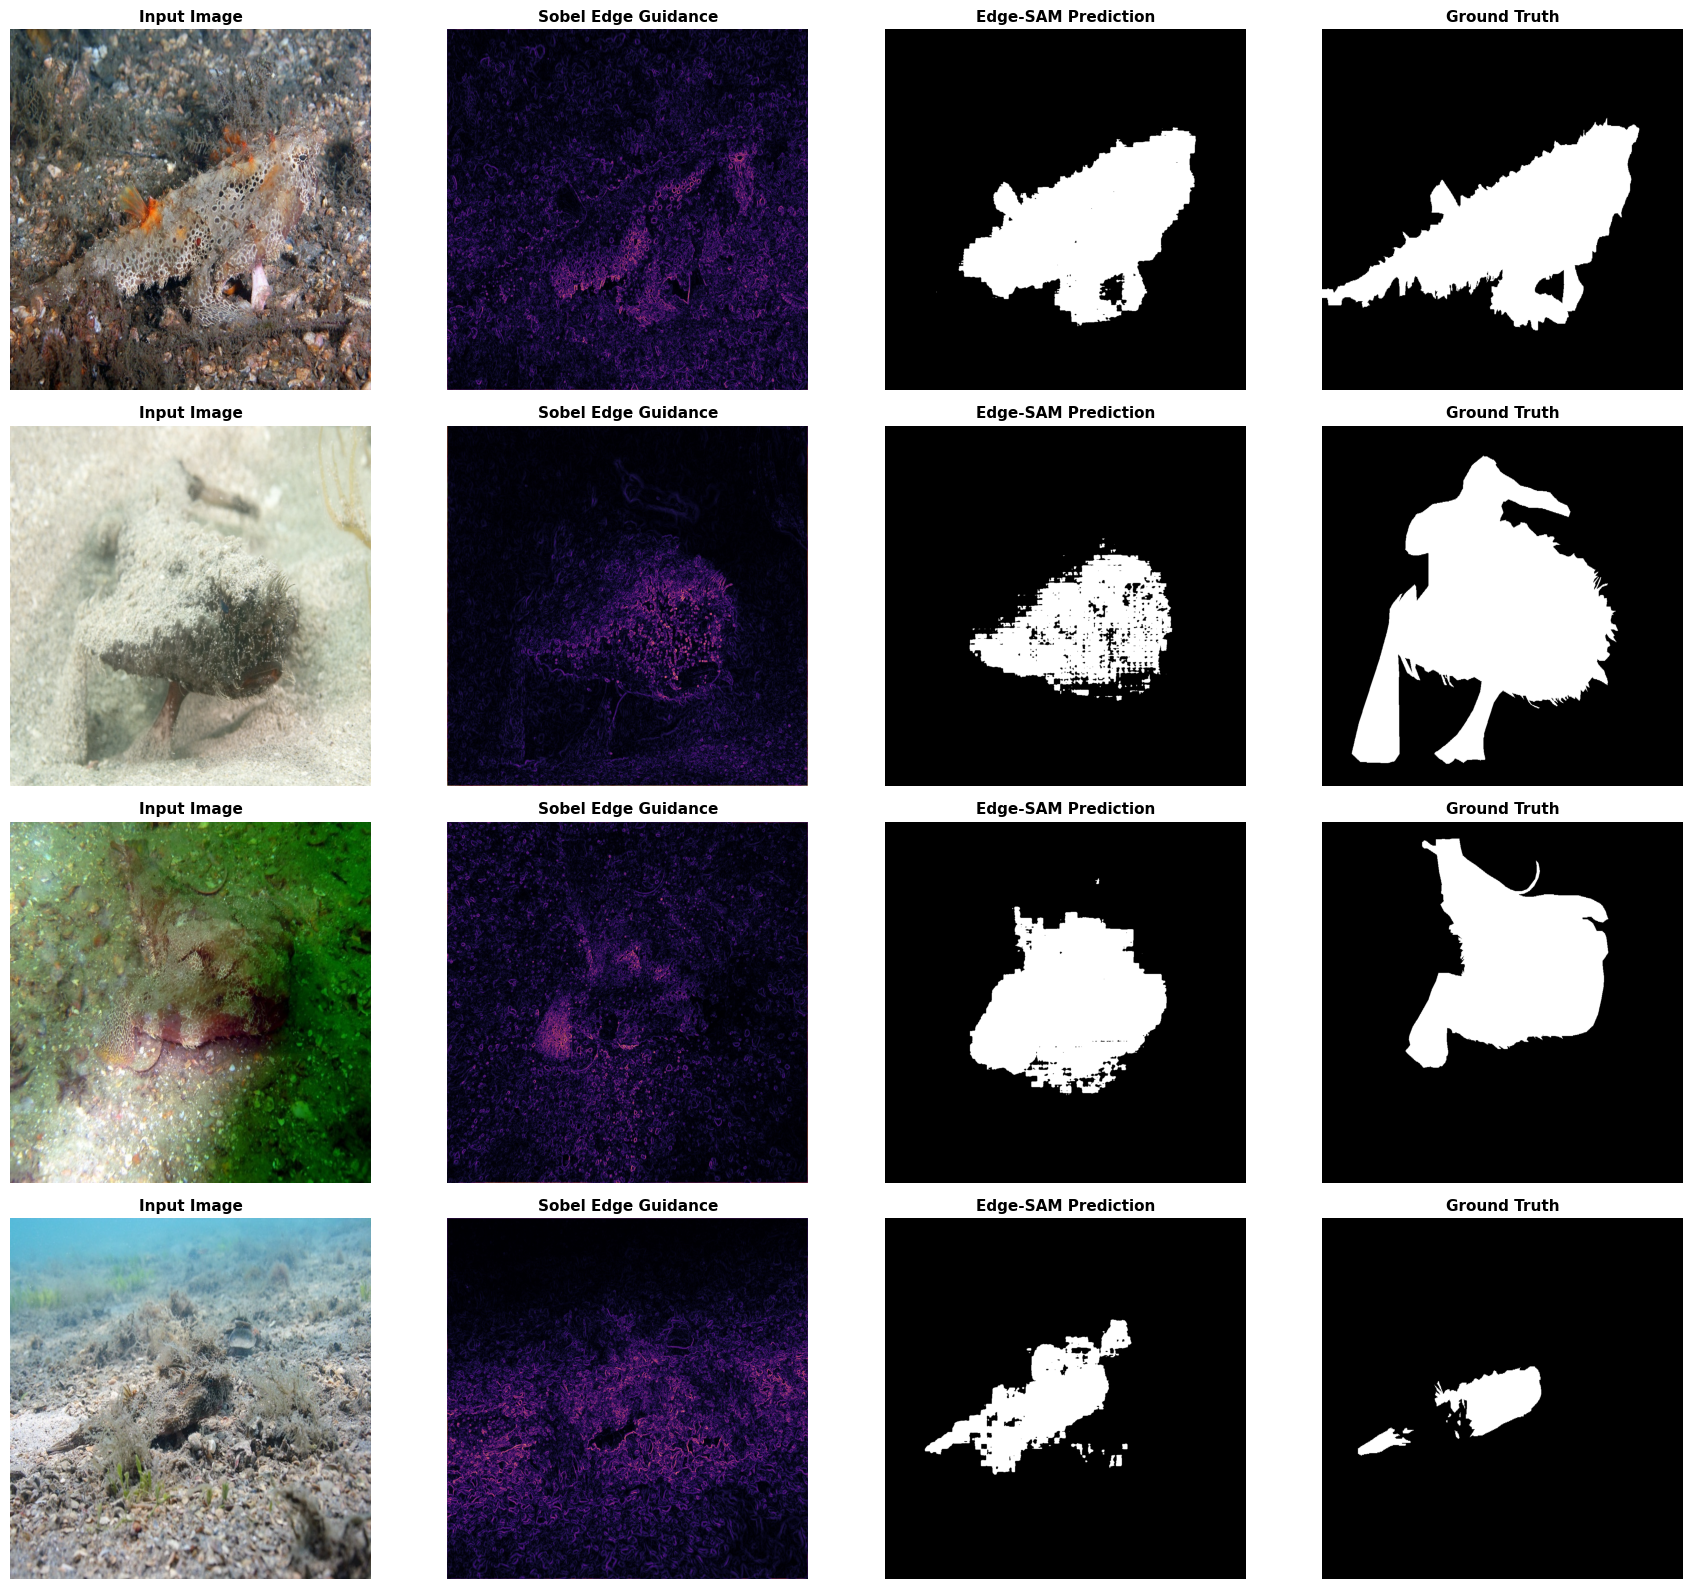

Qualitative figure saved to Drive: qualitative_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()
test_iter = iter(test_loader)

# Select 4 representative samples
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
row = 0

while row < 4:
    imgs, feats, masks = next(test_iter)
    gt_np = masks.squeeze().numpy()

    # Filter for samples containing a camouflaged object (non-empty masks)
    if gt_np.sum() < 500:
        continue

    imgs, feats = imgs.to(device), feats.to(device)

    with torch.no_grad():
        with torch.amp.autocast('cuda', dtype=torch.float16):
            pred_masks, edge_maps = model(imgs, feats)

    pred_prob = torch.sigmoid(pred_masks).squeeze().cpu().numpy()
    edge_np = edge_maps.squeeze().cpu().numpy()

    # Denormalize image for display
    img_display = imgs.squeeze().permute(1, 2, 0).cpu().numpy()
    img_display = img_display * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img_display = np.clip(img_display, 0, 1)

    # Plot Row
    axes[row, 0].imshow(img_display)
    axes[row, 0].set_title("Input Image", fontsize=11, fontweight="bold")

    axes[row, 1].imshow(edge_np, cmap="magma")
    axes[row, 1].set_title("Sobel Edge Guidance", fontsize=11, fontweight="bold")

    axes[row, 2].imshow(pred_prob > 0.5, cmap="gray")
    axes[row, 2].set_title("Edge-SAM Prediction", fontsize=11, fontweight="bold")

    axes[row, 3].imshow(gt_np, cmap="gray")
    axes[row, 3].set_title("Ground Truth", fontsize=11, fontweight="bold")

    for col in range(4):
        axes[row, col].axis("off")

    row += 1

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/COD_Checkpoints/qualitative_comparison.png", dpi=300, bbox_inches='tight')
plt.show()
print("Qualitative figure saved to Drive: qualitative_comparison.png")

In [ ]:
def cal_f_measure_adaptive(pred, gt, beta2=0.3):
    """Standard adaptive F-measure used in COD/SOD papers."""
    # Adaptive threshold: double the mean prediction (clamped to 1.0)
    thresh = min(2.0 * pred.mean(), 1.0)
    pred_bin = (pred >= thresh).astype(np.float32)

    tp = (pred_bin * gt).sum()
    prec = tp / (pred_bin.sum() + 1e-8)
    rec = tp / (gt.sum() + 1e-8)
    if prec + rec == 0:
        return 0.0
    return float(((1 + beta2) * prec * rec) / (beta2 * prec + rec + 1e-8))

In [ ]:
class StructureLoss(nn.Module):
    """Weighted BCE + Weighted IoU/Dice loss (PraNet/SINet-V2 standard)"""
    def __init__(self):
        super().__init__()

    def forward(self, pred, target):
        # pred: raw logits, target: [0, 1]
        prob = torch.sigmoid(pred)

        # Pixel-wise weight based on target perimeter distance
        weit = 1 + 5 * torch.abs(F.avg_pool2d(target, kernel_size=31, stride=1, padding=15) - target)

        # Weighted BCE
        wbce = F.binary_cross_entropy_with_logits(pred, target, reduction='none')
        wbce = (weit * wbce).sum(dim=(2, 3)) / weit.sum(dim=(2, 3))

        # Weighted IoU / Dice
        inter = ((prob * target) * weit).sum(dim=(2, 3))
        union = ((prob + target) * weit).sum(dim=(2, 3))
        wiou = 1.0 - (inter + 1.0) / (union - inter + 1.0)

        return (wbce + wiou).mean()


In [ ]:
import os
import torch
import torch.optim as optim

# 1. Instantiate the new loss
criterion = StructureLoss().to(device)

# 2. Load your current best checkpoint to warm-start
ckpt_path = "/content/drive/MyDrive/COD_Checkpoints/edge_sam_best.pth"
if os.path.exists(ckpt_path):
    print(f"Loading weights from {ckpt_path}...")
    saved_state = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(saved_state['model_state_dict'])
    print("Warm-start weights loaded successfully!")

# 3. Setup optimizer with a slightly lower learning rate for refinement
NUM_FINE_TUNE_EPOCHS = 5
optimizer = optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_FINE_TUNE_EPOCHS, eta_min=1e-6)

best_loss = float('inf')
print(f"Starting refinement training for {NUM_FINE_TUNE_EPOCHS} epochs with StructureLoss...")

for epoch in range(1, NUM_FINE_TUNE_EPOCHS + 1):
    model.train()
    running_loss = 0.0

    for step, (imgs, feats, masks) in enumerate(train_loader):
        imgs, feats, masks = imgs.to(device), feats.to(device), masks.to(device)

        optimizer.zero_grad()
        with torch.amp.autocast('cuda', dtype=torch.float16):
            pred_masks, _ = model(imgs, feats)
            loss = criterion(pred_masks, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if (step + 1) % 250 == 0 or (step + 1) == len(train_loader):
            print(f"Fine-Tune Epoch [{epoch}/{NUM_FINE_TUNE_EPOCHS}] | Step [{step+1}/{len(train_loader)}] | Step Loss: {loss.item():.4f}")

    epoch_avg_loss = running_loss / len(train_loader)
    scheduler.step()
    print(f"---> Epoch {epoch} Complete | Avg Structure Loss: {epoch_avg_loss:.4f}")

    if epoch_avg_loss < best_loss:
        best_loss = epoch_avg_loss
        save_path = "/content/drive/MyDrive/COD_Checkpoints/edge_sam_refined_best.pth"
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'loss': best_loss,
        }, save_path)
        print(f"[*] Saved refined model checkpoint to: {save_path}\n")

print("Refinement training finished!")

Loading weights from /content/drive/MyDrive/COD_Checkpoints/edge_sam_best.pth...
Warm-start weights loaded successfully!
Starting refinement training for 5 epochs with StructureLoss...
Fine-Tune Epoch [1/5] | Step [250/1500] | Step Loss: 1.0050
Fine-Tune Epoch [1/5] | Step [500/1500] | Step Loss: 0.7707
Fine-Tune Epoch [1/5] | Step [750/1500] | Step Loss: 1.0637
Fine-Tune Epoch [1/5] | Step [1000/1500] | Step Loss: 1.1526
Fine-Tune Epoch [1/5] | Step [1250/1500] | Step Loss: 0.9499
Fine-Tune Epoch [1/5] | Step [1500/1500] | Step Loss: 1.1289
---> Epoch 1 Complete | Avg Structure Loss: 0.9485
[*] Saved refined model checkpoint to: /content/drive/MyDrive/COD_Checkpoints/edge_sam_refined_best.pth

Fine-Tune Epoch [2/5] | Step [250/1500] | Step Loss: 0.9811
Fine-Tune Epoch [2/5] | Step [500/1500] | Step Loss: 0.9549
Fine-Tune Epoch [2/5] | Step [750/1500] | Step Loss: 0.8574
Fine-Tune Epoch [2/5] | Step [1000/1500] | Step Loss: 0.9054
Fine-Tune Epoch [2/5] | Step [1250/1500] | Step Loss: 1

In [ ]:
import numpy as np
from tqdm import tqdm

def cal_f_measure_adaptive(pred, gt, beta2=0.3):
    """Standard adaptive F-measure used across COD/SOD literature."""
    thresh = min(2.0 * pred.mean(), 1.0)
    pred_bin = (pred >= thresh).astype(np.float32)

    tp = (pred_bin * gt).sum()
    prec = tp / (pred_bin.sum() + 1e-8)
    rec = tp / (gt.sum() + 1e-8)
    if prec + rec == 0:
        return 0.0
    return float(((1 + beta2) * prec * rec) / (beta2 * prec + rec + 1e-8))

# Load refined checkpoint
refined_ckpt = "/content/drive/MyDrive/COD_Checkpoints/edge_sam_refined_best.pth"
checkpoint = torch.load(refined_ckpt, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

mae_scores = []
sm_scores = []
fm_fixed_scores = []
fm_adp_scores = []
em_scores = []

print(f"Evaluating {len(test_loader)} test samples with refined model...")
with torch.no_grad():
    for imgs, feats, masks in tqdm(test_loader):
        imgs, feats = imgs.to(device), feats.to(device)

        with torch.amp.autocast('cuda', dtype=torch.float16):
            pred_masks, _ = model(imgs, feats)

        prob = torch.sigmoid(pred_masks).squeeze().cpu().numpy()
        gt = masks.squeeze().numpy()
        pred_bin = (prob > 0.5).astype(np.float32)

        mae_scores.append(cal_mae(prob, gt))
        sm_scores.append(cal_s_measure(prob, gt))
        fm_fixed_scores.append(cal_f_measure(pred_bin, gt))
        fm_adp_scores.append(cal_f_measure_adaptive(prob, gt))
        em_scores.append(cal_e_measure(pred_bin, gt))

print("\n======================= COD10K-v3 Refined Benchmark =======================")
print(f"  Structure Measure (S_alpha)       : {np.mean(sm_scores):.4f}")
print(f"  Adaptive F-measure (F_beta^adp)   : {np.mean(fm_adp_scores):.4f}  <-- Standard benchmark metric")
print(f"  Fixed F-measure (F_beta @ 0.5)    : {np.mean(fm_fixed_scores):.4f}")
print(f"  Mean Enhanced-alignment (E_phi)   : {np.mean(em_scores):.4f}")
print(f"  Mean Absolute Error (MAE)         : {np.mean(mae_scores):.4f}")
print("============================================================================")

Evaluating 4000 test samples with refined model...


100%|██████████| 4000/4000 [05:42<00:00, 11.68it/s]


======================= COD10K-v3 Refined Benchmark =======================
  Structure Measure (S_alpha)       : 0.8030
  Adaptive F-measure (F_beta^adp)   : 0.2556  <-- Standard benchmark metric
  Fixed F-measure (F_beta @ 0.5)    : 0.2821
  Mean Enhanced-alignment (E_phi)   : 0.8707
  Mean Absolute Error (MAE)         : 0.0588


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import torch
from tqdm import tqdm

# Load original best checkpoint
best_ckpt = "/content/drive/MyDrive/COD_Checkpoints/edge_sam_best.pth"
checkpoint = torch.load(best_ckpt, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# Metrics tracking
all_sm, all_mae = [], []
pos_fm_fixed, pos_fm_adp = [], []
neg_mae = []

print("Running categorized benchmark on original best model...")
with torch.no_grad():
    for imgs, feats, masks in tqdm(test_loader):
        imgs, feats = imgs.to(device), feats.to(device)

        with torch.amp.autocast('cuda', dtype=torch.float16):
            pred_masks, _ = model(imgs, feats)

        prob = torch.sigmoid(pred_masks).squeeze().cpu().numpy()
        gt = masks.squeeze().numpy()
        pred_bin = (prob > 0.5).astype(np.float32)

        is_positive = gt.sum() > 0

        # Global metrics
        all_sm.append(cal_s_measure(prob, gt))
        all_mae.append(cal_mae(prob, gt))

        if is_positive:
            # Evaluate F-beta exclusively on positive samples
            pos_fm_fixed.append(cal_f_measure(pred_bin, gt))
            pos_fm_adp.append(cal_f_measure_adaptive(prob, gt))
        else:
            neg_mae.append(cal_mae(prob, gt))

print("\n================== Categorized COD10K-v3 Benchmark ==================")
print(f"  Overall S_alpha (All 4000)          : {np.mean(all_sm):.4f}")
print(f"  Overall MAE (All 4000)              : {np.mean(all_mae):.4f}")
print(f"  Background Suppression MAE (Negs)   : {np.mean(neg_mae):.4f}")
print(f"----------------------------------------------------------------------")
print(f"  Positive Object F_beta (Fixed 0.5)  : {np.mean(pos_fm_fixed):.4f}")
print(f"  Positive Object F_beta (Adaptive)   : {np.mean(pos_fm_adp):.4f}")
print("======================================================================")

Running categorized benchmark on original best model...


100%|██████████| 4000/4000 [05:23<00:00, 12.37it/s]


================== Categorized COD10K-v3 Benchmark ==================
  Overall S_alpha (All 4000)          : 0.8218
  Overall MAE (All 4000)              : 0.0482
  Background Suppression MAE (Negs)   : 0.0323
----------------------------------------------------------------------
  Positive Object F_beta (Fixed 0.5)  : 0.6294
  Positive Object F_beta (Adaptive)   : 0.6183
